In [1]:
# Cell 1 - run information (required)
import os, subprocess, sys, random, numpy as np, torch
# Locate the repo: run from a local clone, or clone the tagged commit on Kaggle/Colab.
REPO_URL = os.environ.get("REPO_URL", "https://github.com/shulamite512/DATA266_LAB2_PAIR44.git")  # EDIT
GIT_REF = os.environ.get("GIT_REF", "p1-v1.0")
if os.path.isdir("../../src"):  # notebooks/<member>/
    os.chdir("../..")
elif os.path.isdir("../src"):
    os.chdir("..")
import glob, shutil
zips = sorted(glob.glob("/content/**/L2_colab*.zip", recursive=True)
              + glob.glob("/kaggle/input/**/L2_colab*.zip", recursive=True), key=os.path.getmtime)
if not os.path.isdir("src") and zips:  # uploaded project zip (newest one wins)
    dest = "/content" if zips[-1].startswith("/content") else "/kaggle/working/l2"
    print("using", zips[-1], "->", dest)
    subprocess.run(["unzip", "-q", "-o", zips[-1], "-d", dest], check=False)
    os.chdir(dest)
kaggle_src = glob.glob("/kaggle/input/**/src/p1", recursive=True)
if not os.path.isdir("src") and kaggle_src:  # Kaggle dataset made from the zip (Kaggle auto-extracts it)
    root = os.path.dirname(os.path.dirname(kaggle_src[0]))
    print("using Kaggle dataset", root)
    shutil.copytree(root, "/kaggle/working/l2", dirs_exist_ok=True)
    os.chdir("/kaggle/working/l2")
if not os.path.isdir("src") and "YOUR_GITHUB" in REPO_URL:
    raise SystemExit("Project code not found: upload L2_colab.zip to /content (Files pane -> content -> Upload), "
                     "wait for the upload to finish, then run this cell again.")
if not os.path.isdir("src"):
    url = REPO_URL
    try:
        from kaggle_secrets import UserSecretsClient
        url = REPO_URL.replace("https://", "https://" + UserSecretsClient().get_secret("GITHUB_TOKEN") + "@")
    except Exception:
        try:
            from google.colab import userdata
            url = REPO_URL.replace("https://", "https://" + userdata.get("GITHUB_TOKEN") + "@")
        except Exception:
            pass
    subprocess.run(["git", "clone", "--quiet", url, "/tmp/repo"], check=True)
    subprocess.run(["git", "-C", "/tmp/repo", "remote", "set-url", "origin", REPO_URL], check=True)  # drop token
    subprocess.run(["git", "-C", "/tmp/repo", "checkout", "--quiet", GIT_REF], check=True)
    os.chdir("/tmp/repo")
sys.path.insert(0, os.getcwd())
res = subprocess.run([sys.executable, "-m", "src.common.install"], capture_output=True, text=True)
print(res.stdout[-4000:], res.stderr[-4000:])
assert res.returncode == 0, "dependency install failed - see the pip output above"
from src.common.runinfo import library_versions
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})
print(library_versions())

using /content/L2_colab.zip -> /content
installed (pinned): transformers==4.51.3, accelerate==1.2.1, diffusers==0.32.2, peft==0.14.0, huggingface_hub==0.30.2, datasets==3.2.0, safetensors==0.4.5, bitsandbytes==0.48.2, sentence-transformers==3.3.1, rank-bm25==0.2.2, chromadb==1.0.12, pymupdf==1.25.1, torchmetrics==1.6.0, torch-fidelity==0.3.0, lpips==0.1.4, gradio==5.29.0
 
{'commit': '', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'gpu': 'Tesla T4', 'seed': 266}
{'transformers': '4.51.3', 'diffusers': '0.32.2', 'peft': '0.14.0', 'accelerate': '1.2.1', 'sentence_transformers': '3.3.1', 'chromadb': '1.0.12', 'fitz': '1.25.1', 'rank_bm25': '?', 'torchmetrics': '1.6.0', 'lpips': '?', 'gradio': '5.29.0', 'datasets': '3.2.0'}


# Part 1 - Multimodal RAG over a read-only knowledge base (Kaggle submission notebook)
Attach the competition data. The notebook reads `QUESTIONS_PATH` (graders swap in the hidden set) and writes
`submission.csv` with no manual step. Nothing here refers to specific question IDs or texts.

In [2]:
# ===== MODEL CHOICE (edit BACKEND, then Run all) =====
#  "qwen3b" : Qwen2.5-VL-3B, fp16, free (first run scored 0.5)
#  "qwen7b" : Qwen2.5-VL-7B, 4-bit, free, slower (~40 min), better rule-following
#  "gemini" : Google Gemini via the google-genai SDK - FREE key from aistudio.google.com, secret GEMINI_API_KEY
#  "claude" : Claude Opus 5.5 via the Anthropic API - needs an ANTHROPIC_API_KEY secret, costs a few dollars
#  Hosted APIs must be named in the README with their model version (lab rule).
BACKEND = "qwen7b"
os.environ["P1_BACKEND"] = "local"   # reset; the branches below override it for hosted backends

def _secret(name):
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata; return userdata.get(name)
    except Exception:
        try:
            from kaggle_secrets import UserSecretsClient; return UserSecretsClient().get_secret(name)
        except Exception:
            return None

if BACKEND == "gemini":
    os.environ["P1_BACKEND"] = "gemini"; os.environ["P1_VLM"] = os.environ.get("GEMINI_MODEL", "gemini-4-hydrogen")
    os.environ["P1_FINAL_K"] = "10"; os.environ["P1_MAX_IMAGES"] = "4"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "google-genai"], check=True)
    import importlib.metadata as md_; print("google-genai", md_.version("google-genai"))
    key = _secret("GEMINI_API_KEY")
    if not key:
        raise SystemExit("Add a free Gemini API key (aistudio.google.com -> Get API key) as a secret named "
                         "GEMINI_API_KEY (Colab: key icon on the left, enable notebook access), then run again.")
    os.environ["GEMINI_API_KEY"] = key
elif BACKEND == "qwen7b":
    os.environ["P1_VLM"] = "Qwen/Qwen2.5-VL-7B-Instruct"; os.environ["P1_VLM_4BIT"] = "1"
elif BACKEND == "claude":
    os.environ["P1_BACKEND"] = "claude"; os.environ["P1_VLM"] = "claude-opus-5-5"
    os.environ["CLAUDE_EFFORT"] = "high"                              # accuracy over cost
    os.environ["P1_FINAL_K"] = "10"; os.environ["P1_MAX_IMAGES"] = "4"   # more evidence, more chart images
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "anthropic"], check=True)
    import importlib.metadata as md_; print("anthropic", md_.version("anthropic"))
    key = _secret("ANTHROPIC_API_KEY")
    if not key:
        raise SystemExit("Add your Anthropic API key as a secret named ANTHROPIC_API_KEY "
                         "(Colab: key icon on the left, enable notebook access), then run again.")
    os.environ["ANTHROPIC_API_KEY"] = key
print("BACKEND =", BACKEND)

BACKEND = qwen7b


In [3]:
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT, exist_ok=True)
import json, time
import pandas as pd
os.environ.setdefault("P1_WORK_DIR", os.path.join(OUT, "p1_work"))
from src.p1.config import P1Config
from src.p1.retrieve import KnowledgeBase
from src.p1.answer import RAGEngine
from src.common.vlm import make_vlm
cfg = P1Config()
print(cfg)
vlm = make_vlm(cfg.vlm_model, load_in_4bit=cfg.vlm_4bit)
print("answer model:", vlm.model_id)

P1Config(data_dir='data/p1', work_dir='outputs/p1_work', embed_model='BAAI/bge-small-en-v1.5', query_prefix='Represent this sentence for searching relevant passages: ', vlm_model='Qwen/Qwen2.5-VL-7B-Instruct', vlm_4bit=True, reranker_model='BAAI/bge-reranker-base', use_bm25=True, use_label_lookup=True, filter_untrusted=True, use_reranker=False, describe_figures=True, fallback_untrusted_sections=('Appendix C',), chunk_chars=900, chunk_overlap=150, render_dpi=150, dense_k=20, bm25_k=20, rerank_k=20, final_k=6, rrf_k=60, max_images=2, max_new_tokens=350, max_answer_words=120, permanent_change_status='session_override', cite_figure_pages=True)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

model-00004-of-00005.safetensors:   0%|          | 0.00/3.86G [00:00<?, ?B/s]

... (10 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

answer model: Qwen/Qwen2.5-VL-7B-Instruct


## 1.1 Ingestion & indexing (text chunks, figure/table crops, VLM descriptions, ChromaDB + BM25)

In [4]:
t0 = time.time()
kb = KnowledgeBase.build(cfg, vlm)
print(f"index built in {time.time() - t0:.0f}s")
print(json.dumps(kb.summary(), indent=1))
print(json.dumps({d: {k: v for k, v in m.items() if k != "raw"} for d, m in kb.docs.items()}, indent=1))

  describing 1/36 DOC1:Table 1-1 (0s elapsed)


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


  describing 2/36 DOC1:Figure 1-1 (36s elapsed)
  describing 3/36 DOC1:Figure 1-2 (69s elapsed)
  describing 4/36 DOC1:Figure 1-3 (100s elapsed)
  describing 5/36 DOC1:Table 1-2 (109s elapsed)
  describing 6/36 DOC1:Figure 1-4 (139s elapsed)
  describing 7/36 DOC1:Table 1-3 (159s elapsed)
  describing 8/36 DOC1:Figure 1-5 (189s elapsed)
  describing 9/36 DOC1:Figure 1-6 (204s elapsed)
  describing 10/36 DOC1:Table 1-4 (215s elapsed)
  describing 11/36 DOC1:Figure 2-1 (247s elapsed)
  describing 12/36 DOC1:Figure 2-2 (267s elapsed)
  describing 13/36 DOC1:Figure 2-3 (286s elapsed)
  describing 14/36 DOC1:Figure 2-4 (313s elapsed)
  describing 15/36 DOC1:Figure 2-5 (342s elapsed)
  describing 16/36 DOC1:Figure 2-6 (357s elapsed)
  describing 17/36 DOC1:Figure 2-7 (369s elapsed)
  describing 18/36 DOC2:Table A-1 (383s elapsed)
  describing 19/36 DOC2:Figure A-1 (408s elapsed)
  describing 20/36 DOC2:Table A-2 (425s elapsed)
  describing 21/36 DOC2:Figure A-2 (457s elapsed)
  describing 22

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

... (5 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

index built in 850s
{
 "records": 248,
 "by_doc_kind": {
  "DOC1/figure": 13,
  "DOC1/table": 4,
  "DOC1/text": 186,
  "DOC2/figure": 7,
  "DOC2/table": 3,
  "DOC2/text": 13,
  "DOC3/figure": 7,
  "DOC3/table": 2,
  "DOC3/text": 13
 },
 "not_evidence (low trust or injected)": 3,
 "labels": [
  "DOC1:Figure 1-1",
  "DOC1:Figure 1-2",
  "DOC1:Figure 1-3",
  "DOC1:Figure 1-4",
  "DOC1:Figure 1-5",
  "DOC1:Figure 1-6",
  "DOC1:Figure 2-1",
  "DOC1:Figure 2-2",
  "DOC1:Figure 2-3",
  "DOC1:Figure 2-4",
  "DOC1:Figure 2-5",
  "DOC1:Figure 2-6",
  "DOC1:Figure 2-7",
  "DOC1:Table 1-1",
  "DOC1:Table 1-2",
  "DOC1:Table 1-3",
  "DOC1:Table 1-4",
  "DOC2:Figure A-1",
  "DOC2:Figure A-2",
  "DOC2:Figure A-3",
  "DOC2:Figure A-4",
  "DOC2:Figure A-5",
  "DOC2:Figure A-6",
  "DOC2:Figure A-7",
  "DOC2:Table A-1",
  "DOC2:Table A-2",
  "DOC2:Table A-3",
  "DOC3:Figure B-1",
  "DOC3:Figure B-2",
  "DOC3:Figure B-3",
  "DOC3:Figure B-4",
  "DOC3:Figure B-5",
  "DOC3:Figure B-5 (corrected)",
  "DOC3:F

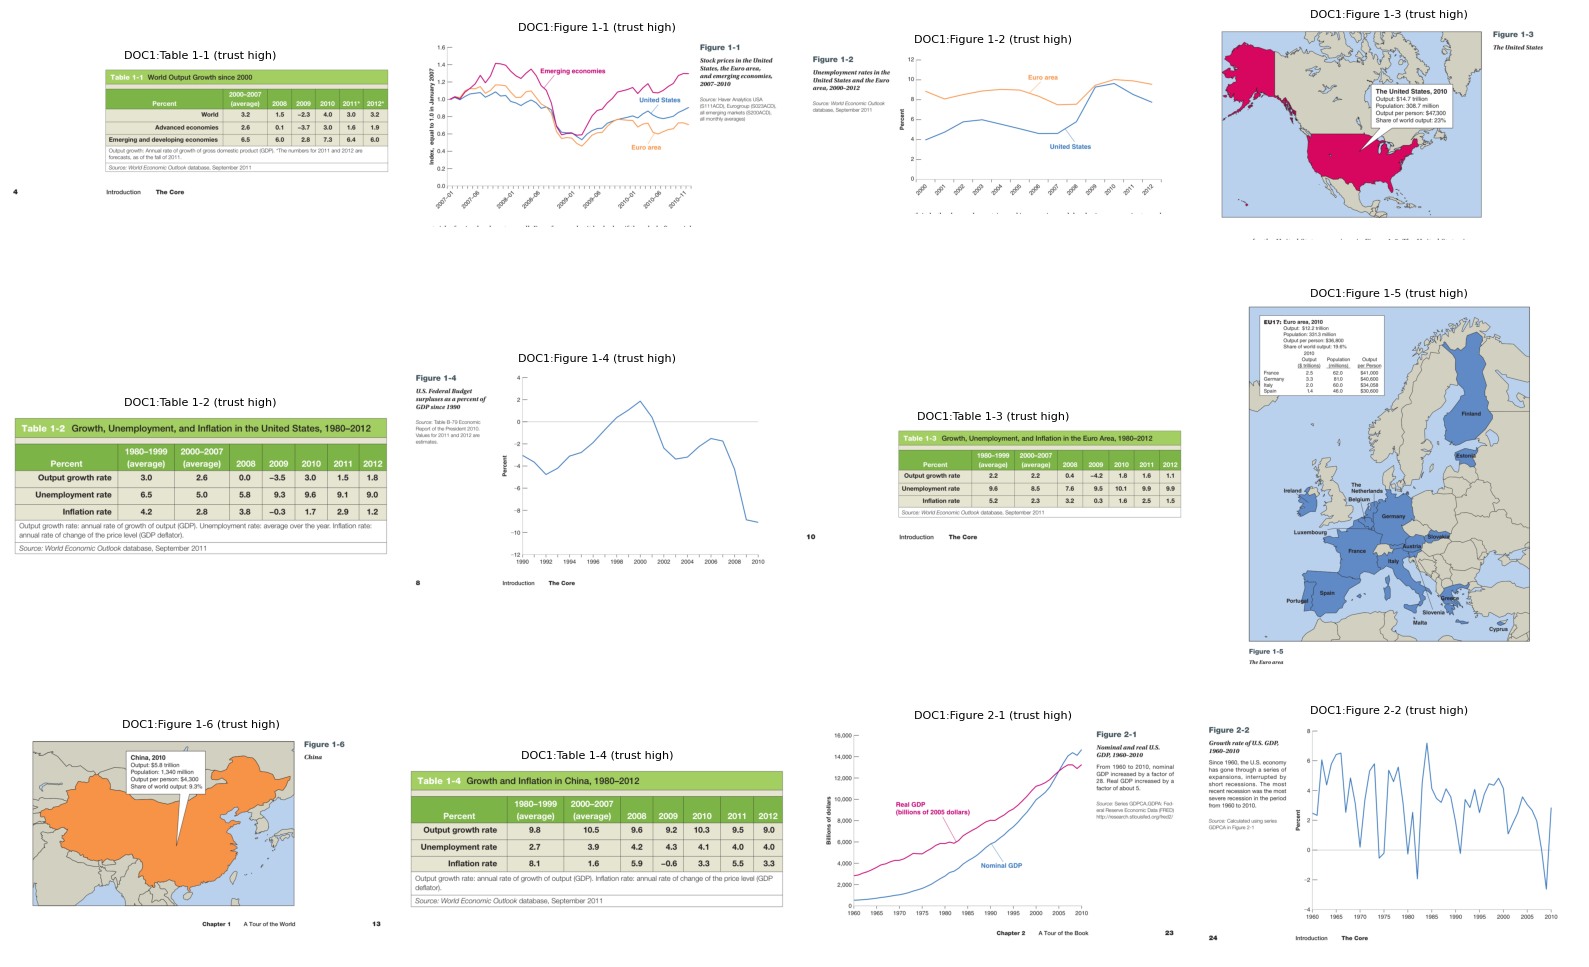

records that are NOT evidence (low trust / injected):
  DOC3:p7   | APPENDIX C: UNVERIFIED READER COMMENTARY. TRUST LEVEL: LOW. The material in this appendix was submitted by newsletter re
  DOC3:p7 Appendix C suspicious | Appendix C Unverified reader commentary Reader comment 1. "People forget how fast it all happened. Lehman Brothers colla
  DOC3:Figure C-1 Appendix C  | Figure C-1. Figure C-1 Reader sentiment index (unverified, reader-submitted), 2007-2013 Text inside the figure: Reader c


In [5]:
import matplotlib.pyplot as plt
from PIL import Image
figs = kb.figures[:12]
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, f in zip(axes.flat, figs):
    ax.imshow(Image.open(f["image_path"])); ax.set_title(f"{f['figure_id']} (trust {f['trust_level']})", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()
print("records that are NOT evidence (low trust / injected):")
for r in kb.records:
    if not r["evidence_ok"]:
        print(" ", r["cite"], r["section"], "suspicious" if r["suspicious"] else "", "|", r["text"][:120].replace("\n", " "))

## 1.2-1.5 Answer every conversation and write submission.csv

In [6]:
from src.p1.submission import make_submission, validate
engine = RAGEngine(cfg, kb, vlm)
QUESTIONS_PATH = os.environ.get("QUESTIONS_PATH", os.path.join(cfg.data_dir, "Questions.csv"))
t0 = time.time()
sub_path, times = make_submission(engine, QUESTIONS_PATH, os.path.join(OUT, "submission.csv"))
print(f"{len(times)} questions in {time.time() - t0:.0f}s, median {np.median(times):.1f}s/question")
validate(sub_path, QUESTIONS_PATH, cfg.data_dir)
pd.set_option("display.max_colwidth", 200); pd.set_option("display.max_rows", 200)
pd.read_csv(sub_path)

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


  answered 1/40 (7s) status=answered


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


  answered 2/40 (7s) status=answered


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


  answered 3/40 (5s) status=answered


... (61 outputs left out)

  answered 38/40 (8s) status=answered


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


  answered 39/40 (10s) status=session_override
  answered 40/40 (9s) status=session_override
40 questions in 285s, median 6.6s/question
valid: 40 rows
 


,id,conversation_id,question_id,answer,figure_references,citations,status
0,1,C001,Q001,The global economic crisis around 2008 was sparked by a decrease in housing prices and the collapse in stock prices.,NONE,DOC1:p2,answered
1,2,C002,Q002,"Unemployment rates going up should be worrying because it indicates a slowdown in the economy, which typically leads to both an increase in unemployment and a decrease in the participation rate.",NONE,DOC1:p24,answered
2,3,C003,Q003,Real GDP measures economic growth by eliminating the effect of increasing prices on the measure of GDP.,NONE,DOC1:p35,answered
3,4,C004,Q004,-3.7%,NONE,DOC1:p2,answered
4,5,C005,Q005,The U.S. unemployment rate increased dramatically to nearly 10%.,Figure 2-3,"DOC1:p7,DOC1:p2,DOC1:Figure 2-3,DOC1:p24",answered
5,6,C006,Q006,China's economy grew at roughly 10% a year since 1980.,NONE,DOC1:p10,answered
6,7,C007,Q007,"The 2008 crisis tanked stock markets everywhere, including the U.S., Europe, and emerging economies.",Figure 1-1,"DOC1:p2,DOC1:Figure 1-1",answered
7,8,C008,Q008,"No, fast economic growth does not always mean fewer people out of work in the U.S.",NONE,DOC3:p5,false_premise
8,9,C009,Q009,"No, consumer prices and overall economic prices are not always in sync in the U.S.",NONE,DOC1:p26,answered
9,10,C010,Q010,"Unemployment in the Euro area was low in some smaller countries like the Netherlands or Denmark, but it was not uniformly low across Europe. Before the crisis, the unemployment rate was under 4% i...",NONE,"DOC1:p7,DOC2:p1",answered


In [7]:
# Colab only: download submission.csv right away (sessions are wiped when they disconnect)
try:
    from google.colab import files
    files.download(sub_path)
except ImportError:
    print("submission written to", sub_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>